## ANN Replication: Stage C
- evaluation of network (evaluation.py) (stage C)

In [1]:
import sys
from pathlib import Path

import numpy as np

# repo root: works whether the notebook is opened from notebooks/ or from the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))     # lets us import the sandwich package even without pip install

DATA_NPZ = ROOT / "data/processed/prepared.npz"     # Week 4 output: normalised and split
MODEL_DIR = ROOT / "models/ann_baseline"            # hand-off folder between 05a, 05b and 05c
MODEL_DIR.mkdir(parents=True, exist_ok=True)

import json

import matplotlib.pyplot as plt
import pandas as pd

from sandwich.ann.network import OUTPUT_COLS, INPUT_COLS, load_model, load_split, predict, r_squared

OUT_FIG = ROOT / "results/figures"
OUT_TAB = ROOT / "results/tables"
for d in (OUT_FIG, OUT_TAB):
    d.mkdir(parents=True, exist_ok=True)

data = load_split(DATA_NPZ)
w_best, meta = load_model(MODEL_DIR)
history = pd.read_csv(MODEL_DIR / "history.csv")

# warn if the dataset has changed since this model was trained
import hashlib
if hashlib.md5(DATA_NPZ.read_bytes()).hexdigest() != meta["data_md5"]:
    print("WARNING: prepared.npz has changed since this model was trained. Rerun 05a and 05b.")
print(f"model: best epoch {meta['best_epoch']}, stopped by '{meta['stop_reason']}' after {meta['epochs_run']} epochs")

model: best epoch 1000, stopped by 'maximum epochs reached' after 1000 epochs


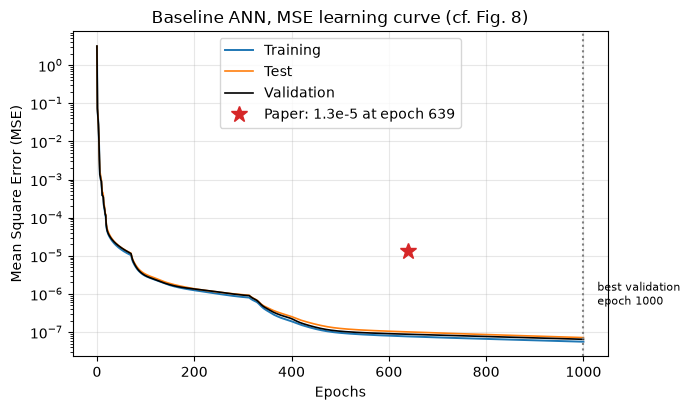

best validation epoch 1000, validation MSE 6.456e-08   (paper: 1.3e-05 at 639)


In [2]:
best_epoch = meta["best_epoch"]
best_val = history.loc[history.epoch == best_epoch, "val"].iloc[0]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.semilogy(history.epoch, history.train, label="Training", lw=1.4)
ax.semilogy(history.epoch, history.test, label="Test", lw=1.2)
ax.semilogy(history.epoch, history.val, label="Validation", lw=1.2, color="k")
ax.axvline(best_epoch, ls=":", color="grey")
ax.annotate(f"best validation\nepoch {best_epoch}", (best_epoch, best_val),
            xytext=(10, 25), textcoords="offset points", fontsize=8)
ax.plot(639, 1.3e-5, marker="*", ms=12, color="tab:red", ls="none", label="Paper: 1.3e-5 at epoch 639")
ax.set_xlabel("Epochs")
ax.set_ylabel("Mean Square Error (MSE)")
ax.set_title("Baseline ANN, MSE learning curve (cf. Fig. 8)")
ax.grid(True, which="major", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_FIG / "week5_mse_learning_curve.png", dpi=150)
plt.show()

print(f"best validation epoch {best_epoch}, validation MSE {best_val:.3e}   (paper: 1.3e-05 at 639)")

training    pooled R² = 1.00000   MSE = 5.588e-08
test        pooled R² = 1.00000   MSE = 7.168e-08
validation  pooled R² = 1.00000   MSE = 6.456e-08


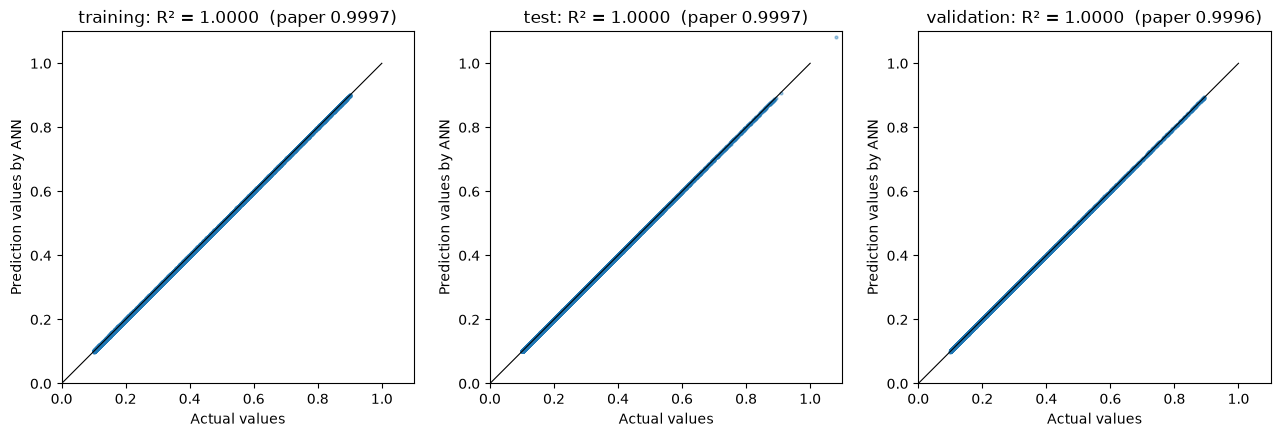

In [3]:
sets = {"training": "train", "test": "test", "validation": "val"}
paper_r2 = {"training": 0.9997, "test": 0.9997, "validation": 0.9996}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (name, p) in zip(axes, sets.items()):
    X, Y = data[f"X_{p}"], data[f"Y_{p}"]
    P = predict(w_best, X)
    r2 = r_squared(Y, P)
    ax.scatter(Y.ravel(), P.ravel(), s=4, alpha=0.4)
    ax.plot([0, 1], [0, 1], color="k", lw=0.8)
    ax.set(xlim=(0, 1.1), ylim=(0, 1.1), xlabel="Actual values", ylabel="Prediction values by ANN",
           title=f"{name}: R² = {r2:.4f}  (paper {paper_r2[name]})")
    ax.set_aspect("equal")
    print(f"{name:<11} pooled R² = {r2:.5f}   MSE = {np.mean((P - Y) ** 2):.3e}")
fig.tight_layout()
fig.savefig(OUT_FIG / "week5_parity_pooled.png", dpi=150)
plt.show()

In [4]:
X_te, Y_te = data["X_test"], data["Y_test"]
P_te = predict(w_best, X_te)
per_output = pd.DataFrame({
    "output": OUTPUT_COLS,
    "R2_test": [r_squared(Y_te[:, k], P_te[:, k]) for k in range(8)],
    "MSE_test": [np.mean((P_te[:, k] - Y_te[:, k]) ** 2) for k in range(8)],
}).set_index("output")
per_output.to_csv(OUT_TAB / "week5_per_output_test.csv")
per_output.style.format({"R2_test": "{:.5f}", "MSE_test": "{:.2e}"})

,R2_test,MSE_test
output,,
SF_c,1.00000,2.65e-08
SF_f,0.99998,1.16e-07
SF_int,0.99998,2.53e-07
SF_wr,1.00000,6.78e-08
C_delta,0.99999,7.55e-08
t_sw,1.00000,5.57e-09
C_t,1.00000,1.22e-08
W_t,1.00000,1.68e-08


In [5]:
from sandwich.config import load_materials, load_problem
from sandwich.sampling import evaluate_designs
from sandwich.solver import Panel, evaluate

with open(ROOT / "data/processed/scalers.json") as f:
    sc = json.load(f)


# Eq. 16 forwards: physical -> normalised
def to_norm(Z, part):
    lo, hi = np.array(sc[part]["zmin"]), np.array(sc[part]["zmax"])
    return sc[part]["lam1"] + (sc[part]["lam2"] - sc[part]["lam1"]) * (Z - lo) / (hi - lo)


# Eq. 16 backwards: normalised -> physical
def to_phys(Xn, part):
    lo, hi = np.array(sc[part]["zmin"]), np.array(sc[part]["zmax"])
    return lo + (Xn - sc[part]["lam1"]) * (hi - lo) / (sc[part]["lam2"] - sc[part]["lam1"])


# the three Table 6 designs at the nominal load, in the ANN's input order
prob = load_problem()
p_nom = prob["nominal_case"]["p"]["value"]
designs = prob["reference_designs"]
Z_in = pd.DataFrame([{"rho_c": d["rho_c"]["value"], "t_c": d["tc"]["value"],
                      **{f"L{k + 1}": c for k, c in enumerate(d["layup"])}, "p": p_nom}
                     for d in designs.values()], index=list(designs))[INPUT_COLS]

# ANN: normalise inputs, predict, convert outputs back to physical units
ann = pd.DataFrame(to_phys(predict(w_best, to_norm(Z_in.to_numpy(float), "X")), "Y"),
                   index=Z_in.index, columns=OUTPUT_COLS)

# analytical solver on the same three designs
analytical = evaluate_designs(Z_in.reset_index(drop=True))[OUTPUT_COLS]
analytical.index = Z_in.index

# side by side, one row per output
comparison = pd.concat({"analytical": analytical, "ANN": ann}, axis=1)
comparison = comparison.swaplevel(axis=1).sort_index(axis=1, level=0)[OUTPUT_COLS]
comparison.T.style.format("{:.4g}")

In [6]:
MATERIALS, CORES = load_materials()
panel = Panel()
table7 = {"min_weight": (1.965, 27.53), "min_cost": (1.869, 14.71), "knee_point": (1.984, 21.30)}

rows = []
for name, d in designs.items():
    resp = evaluate([MATERIALS[c] for c in d["layup"]], CORES[d["rho_c"]["value"]],
                    d["tc"]["value"], p_nom, panel=panel)
    rows.append({
        "design": name,
        "delta analytical [mm]": resp.delta,
        "delta ANN [mm]": ann.loc[name, "C_delta"] * panel.l / 400,            # from Eq. 26
        "delta paper [mm]": table7[name][0],
        "sigma_f analytical [MPa]": resp.sigma_f,
        "sigma_f ANN [MPa]": resp.sigma_fx / ann.loc[name, "SF_f"],          # sigma_fx / SF_f
        "sigma_f paper [MPa]": table7[name][1],
    })
table7_check = pd.DataFrame(rows).set_index("design")
table7_check.to_csv(OUT_TAB / "week5_table7_ann_vs_analytical.csv")
table7_check.style.format("{:.3f}")

,delta analytical [mm],delta ANN [mm],delta paper [mm],sigma_f analytical [MPa],sigma_f ANN [MPa],sigma_f paper [MPa]
design,,,,,,
min_weight,2.010,2.018,1.965,27.683,27.976,27.530
min_cost,1.833,1.802,1.869,14.798,14.741,14.710
knee_point,2.030,2.024,1.984,21.416,21.377,21.300
